# Bayesian inference of the squeezing parameter (two-scheme version)

Updated copy of `bayesian_inference.ipynb`, which is left unchanged. Changes:

- all simulation and measurement physics comes from `simulate.py` instead of being pasted or re-derived here: data from `sample_measurements` / `sample_calibration`, and every likelihood covariance from `observed_covariance` (eq. Sobs of Section 3.1), so the models stay in sync with the simulator;
- homodyne is removed: the simulator now models only **joint** (idealized benchmark) and **heterodyne** (physical case), see Section 3.1;
- the per-quadrature likelihood with NaN masking is replaced by a bivariate normal with covariance `observed_covariance(...)`, the same likelihood since both quadratures are observed in every shot;
- MCMC progress bars are turned off, so re-running the notebook does not rewrite their output in the saved file;
- duplicate imports are merged into the first cell, and the empty last cell is removed.

Priors and MCMC settings are otherwise unchanged.

In [1]:
import numpyro
numpyro.set_host_device_count(4)  # run the 4 chains in parallel on CPU; must precede any JAX computation

import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from jax import random
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az
import matplotlib.pyplot as plt

from simulate import (generate_covariance_matrix, reduce_to_accessible, observed_covariance,
                      sample_measurements, sample_calibration)

C:\Users\kanci\OneDrive\Dokumenty\GitHub\Gaussian-State-Tomography-of-Hawking-Unruh-Toy-Radiation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\kanci\OneDrive\Dokumenty\GitHub\Gaussian-State-Tomography-of-Hawking-Unruh-Toy-Radiation\.venv\Lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
r_true = 0.5
noise_level = 0.1

V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=noise_level,
    measurement_type="joint",
    key=jax.random.PRNGKey(0), # or random.key(0)
)

In [3]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0, 1))
    Sigma_obs = observed_covariance(r, noise_level, "joint")  # V_A(r) + sigma^2 I_2

    numpyro.sample("X_obs", dist.MultivariateNormal(loc=jnp.zeros(2), covariance_matrix=Sigma_obs), obs=X_obs)

In [4]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
    progress_bar=False,
)
mcmc.run(rng_key, X_obs=samples)
posterior_samples = mcmc.get_samples()["r"]

array([[<Axes: title={'center': 'r'}>, <Axes: title={'center': 'r'}>]],
      dtype=object)

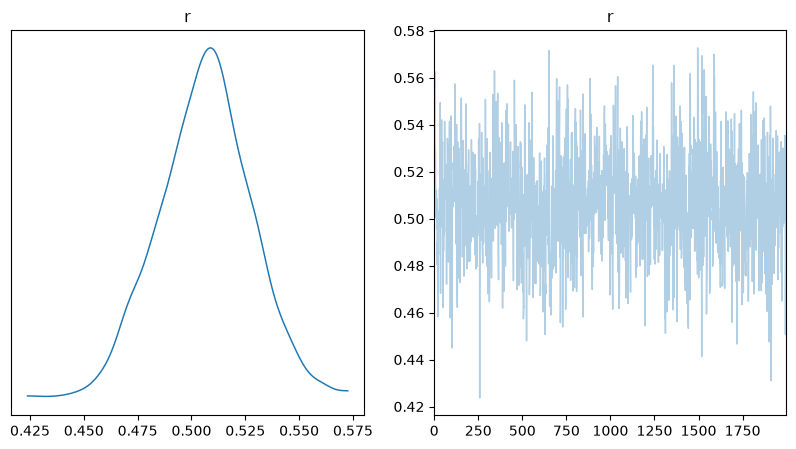

In [5]:
data = az.from_numpyro(mcmc)
az.plot_trace(data, compact=True, figsize=(10, 5))

In [6]:
posterior_mean = jnp.mean(posterior_samples)
posterior_mean

Array(0.50621134, dtype=float32)

***

In [7]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000

rng = jax.random.PRNGKey(0)

# Full two-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=noise_true,
    measurement_type="joint",
    key=rng, # or random.key(0)
)

In [8]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
    noise = numpyro.sample("noise", dist.HalfNormal(1.0))

    Sigma_obs = observed_covariance(r, noise, "joint")  # V_A(r) + noise^2 I_2

    numpyro.sample("X_obs", dist.MultivariateNormal(loc=jnp.zeros(2), covariance_matrix=Sigma_obs), obs=X_obs)

In [9]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model, target_accept_prob=0.9)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
    num_chains=4,
    progress_bar=False,
)
mcmc.run(rng_key, X_obs=samples)

posterior_samples = mcmc.get_samples()
r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

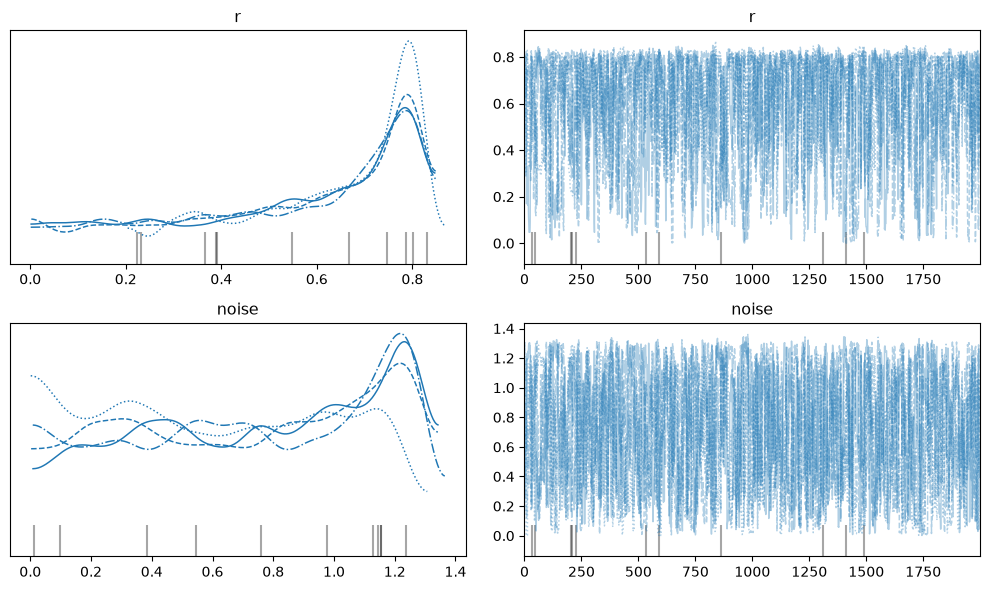

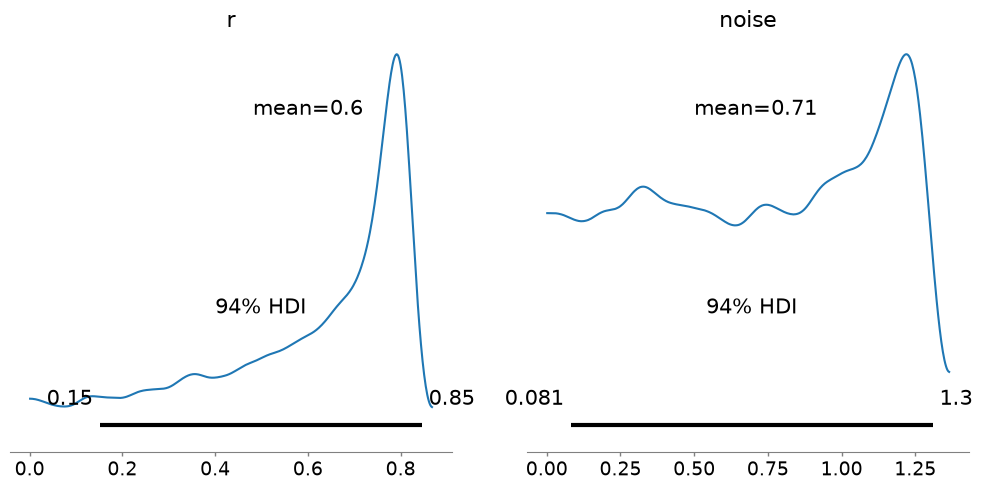

C:\Users\kanci\AppData\Local\Temp\ipykernel_9256\993155245.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


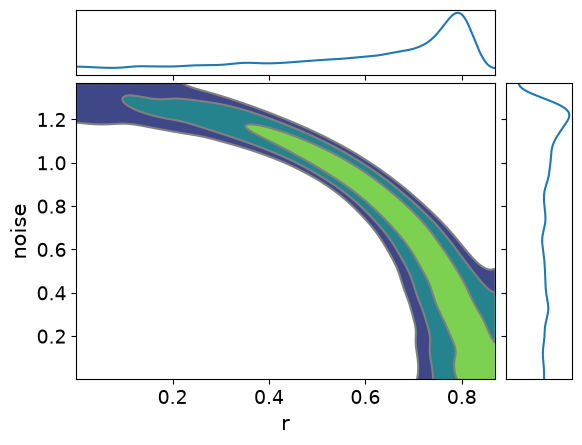

In [10]:
data = az.from_numpyro(mcmc)

az.plot_trace(
    data,
    var_names=["r", "noise"],
    compact=True,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()


az.plot_posterior(
    data,
    var_names=["r", "noise"],
    ref_val=None,
    figsize=(10, 5)
)

plt.tight_layout()
plt.show()


az.plot_pair(
    data,
    var_names=["r", "noise"],
    kind="kde",
    marginals=True
)

plt.tight_layout()
plt.show()


In [11]:
summary = az.summary(
    data,
    var_names=["r", "noise"],
    hdi_prob=0.90
)

print(summary)

        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.600  0.220   0.239    0.844      0.008    0.005     770.0    1176.0   
noise  0.708  0.392   0.141    1.307      0.013    0.005     849.0    1083.0   

       r_hat  
r       1.02  
noise   1.02  


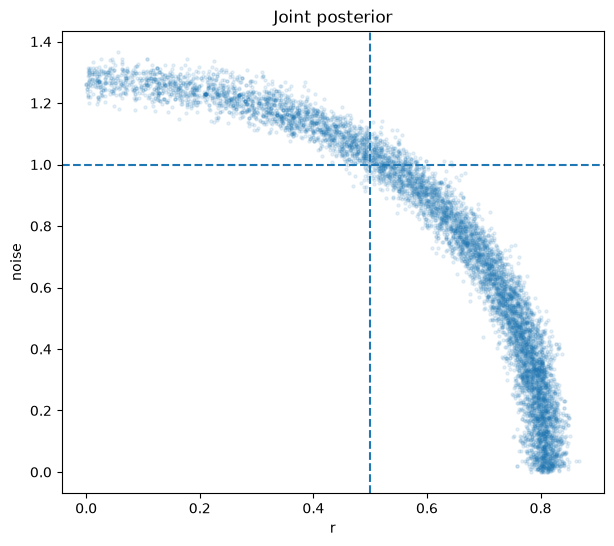

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(
    jnp.array(posterior_samples["r"]),
    jnp.array(posterior_samples["noise"]),
    alpha=0.1,
    s=5
)

plt.axvline(r_true, linestyle="--")
plt.axhline(noise_true, linestyle="--")

plt.xlabel("r")
plt.ylabel("noise")
plt.title("Joint posterior")

plt.show()

In [13]:
posterior_samples = mcmc.get_samples()

r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

# total observed variance per quadrature, Sigma_obs[0, 0] = cosh(2r) + noise^2
total_variance = jax.vmap(
    lambda r, s: observed_covariance(r, s, "joint")[0, 0]
)(r_samples, noise_samples)

print("Posterior mean total variance:",
      float(jnp.mean(total_variance)))

print("True total variance:",
      float(observed_covariance(r_true, noise_true, "joint")[0, 0]))

Posterior mean total variance: 2.627213954925537
True total variance: 2.5430805683135986


When both the squeezing parameter (r) and detector noise ($\sigma$) are treated as unknown, Bayesian inference successfully recovers the total observed variance. However, (r) and ($\sigma$) are only weakly identifiable individually because both parameters contribute to the same isotropic variance term

***
## Signal + vacuum calibration, joint and heterodyne

In [14]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000
n_calibration = 1000
seed = 0
key_signal, key_cal = random.split(random.key(seed))
# Accessible one-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

print("True r:", r_true)
print("True detector noise:", noise_true)
print("Accessible covariance:\n", V_A)

measurement_types = ["joint", "heterodyne"]

datasets = {}

for i, mt in enumerate(measurement_types):

    # Independent keys for every signal/calibration run
    key_signal_i, key_cal_i = random.split(
        random.fold_in(key_signal, i)
    )

    # Signal data: state + measurement effects + detector noise
    X_obs = sample_measurements(
        V_A,
        n_samples=n_samples,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_signal_i,
    )

    # Vacuum calibration: no unknown squeezing signal
    calibration_data = sample_calibration(
        n_calibration=n_calibration,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_cal_i,
        source="vacuum",
    )

    datasets[mt] = {
        "X_obs": X_obs,
        "calibration_data": calibration_data,
    }

    print(f"\n{mt}")
    print("Signal shape:", X_obs.shape)
    print("Calibration shape:", calibration_data.shape)


True r: 0.5
True detector noise: 1.0
Accessible covariance:
 [[1.5430806 0.       ]
 [0.        1.5430806]]

joint
Signal shape: (1000, 2)
Calibration shape: (1000, 2)

heterodyne
Signal shape: (1000, 2)
Calibration shape: (1000, 2)


In [15]:
def make_model(measurement_type):

    mt = measurement_type

    def model(X_obs, calibration_data):
        r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
        noise = numpyro.sample("noise", dist.HalfNormal(1.0))

        # Signal likelihood: Sigma_obs(r) from the simulator's measurement model,
        # including the extra unit of vacuum noise for heterodyne
        signal_cov = observed_covariance(r, noise, mt)
        numpyro.sample(
            "X_obs",
            dist.MultivariateNormal(loc=jnp.zeros(2), covariance_matrix=signal_cov),
            obs=X_obs,
        )

        # Vacuum calibration likelihood: the same measurement chain applied to
        # the vacuum, i.e. the r = 0 state
        calibration_cov = observed_covariance(0.0, noise, mt)
        numpyro.sample(
            "calibration",
            dist.MultivariateNormal(loc=jnp.zeros(2), covariance_matrix=calibration_cov),
            obs=calibration_data,
        )

    return model

In [16]:
results = {}

for i, mt in enumerate(measurement_types):

    print(f"\n{'=' * 55}")
    print(f"Running inference: {mt}")
    print(f"{'=' * 55}")

    model_mt = make_model(mt)

    kernel = NUTS(
        model_mt,
        target_accept_prob=0.9
    )

    mcmc = MCMC(
        kernel,
        num_warmup=1000,
        num_samples=2000,
        num_chains=4,
        progress_bar=False,
    )

    run_key = random.fold_in(random.key(100), i)

    mcmc.run(
        run_key,
        X_obs=datasets[mt]["X_obs"],
        calibration_data=datasets[mt]["calibration_data"],
    )

    results[mt] = mcmc

    # Diagnostics
    idata = az.from_numpyro(mcmc)

    print(f"\nPosterior summary: {mt}")

    print(
        az.summary(
            idata,
            var_names=["r", "noise"],
            hdi_prob=0.90,
        )
    )


Running inference: joint



Posterior summary: joint
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.492  0.045   0.423    0.569      0.001    0.001    3425.0    3720.0   
noise  1.004  0.032   0.950    1.053      0.001    0.000    3315.0    3686.0   

       r_hat  
r        1.0  
noise    1.0  

Running inference: heterodyne



Posterior summary: heterodyne
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.501  0.066   0.398    0.607      0.001    0.001    3122.0    3678.0   
noise  1.025  0.048   0.946    1.104      0.001    0.001    2905.0    2815.0   

       r_hat  
r        1.0  
noise    1.0  


In [17]:
summary_rows = []

for mt, mcmc in results.items():

    posterior = mcmc.get_samples()

    r_samples = np.asarray(posterior["r"])
    noise_samples = np.asarray(posterior["noise"])

    r_ci = np.percentile(r_samples, [5, 95])
    noise_ci = np.percentile(noise_samples, [5, 95])

    summary_rows.append({
        "measurement": mt,
        "r_mean": r_samples.mean(),
        "r_sd": r_samples.std(),
        "r_90%_low": r_ci[0],
        "r_90%_high": r_ci[1],
        "noise_mean": noise_samples.mean(),
        "noise_sd": noise_samples.std(),
        "noise_90%_low": noise_ci[0],
        "noise_90%_high": noise_ci[1],
    })

summary_df = pd.DataFrame(summary_rows)

print("\nTrue r:", r_true)
print("True noise:", noise_true)

print("\nComparison of measurement schemes:")
print(summary_df.round(3).to_string(index=False))


True r: 0.5
True noise: 1.0

Comparison of measurement schemes:
measurement  r_mean  r_sd  r_90%_low  r_90%_high  noise_mean  noise_sd  noise_90%_low  noise_90%_high
      joint   0.492 0.045      0.415       0.563       1.004     0.032          0.952           1.055
 heterodyne   0.501 0.066      0.387       0.600       1.025     0.048          0.946           1.104


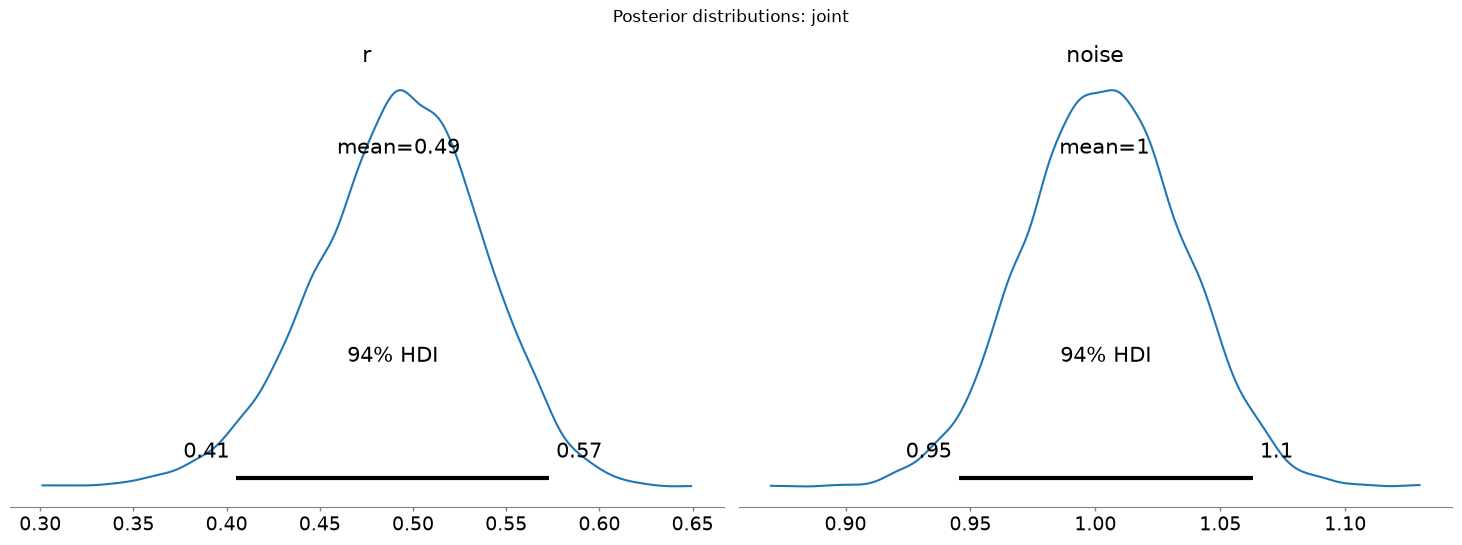

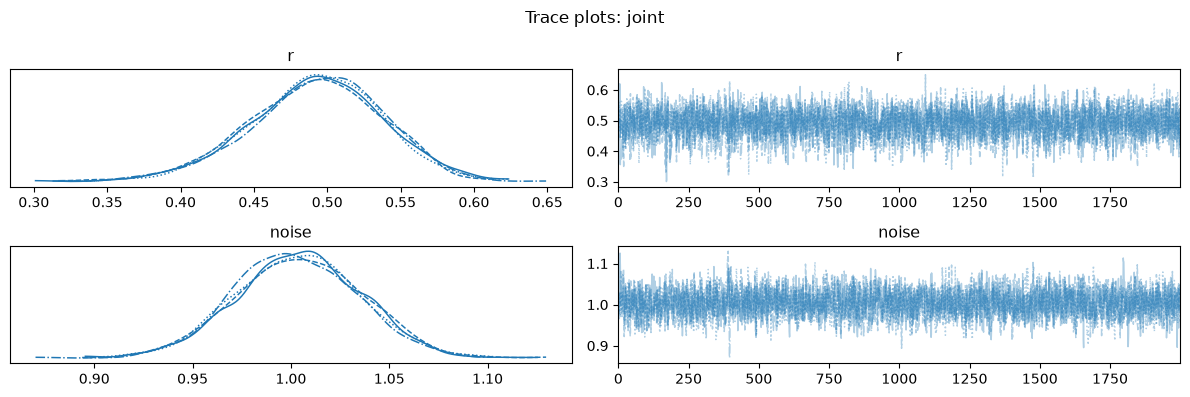

C:\Users\kanci\AppData\Local\Temp\ipykernel_9256\657810364.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


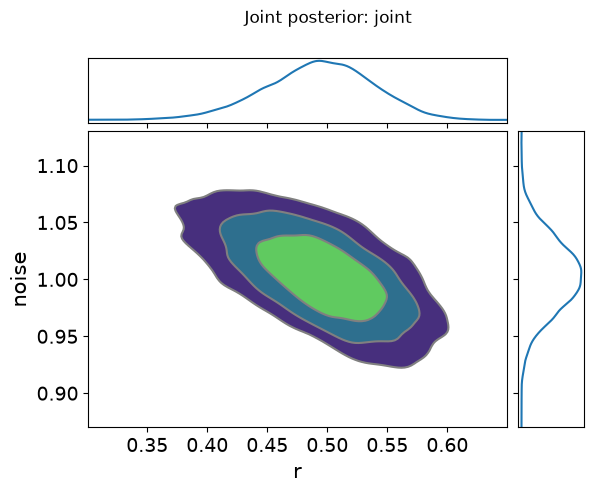

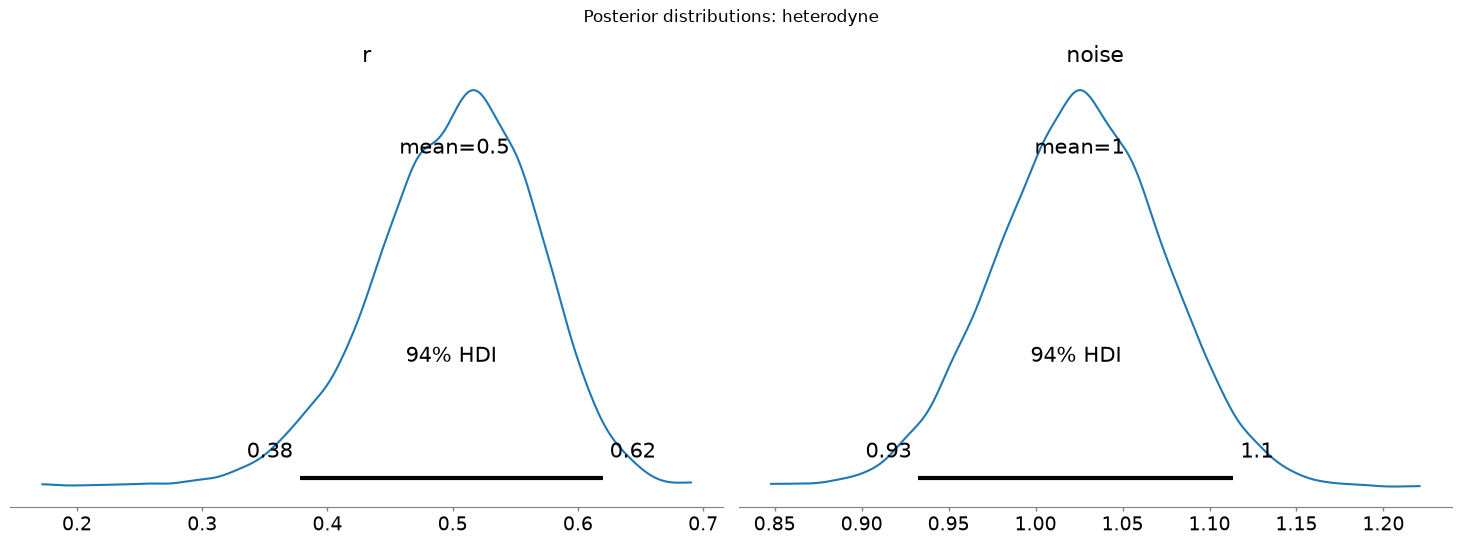

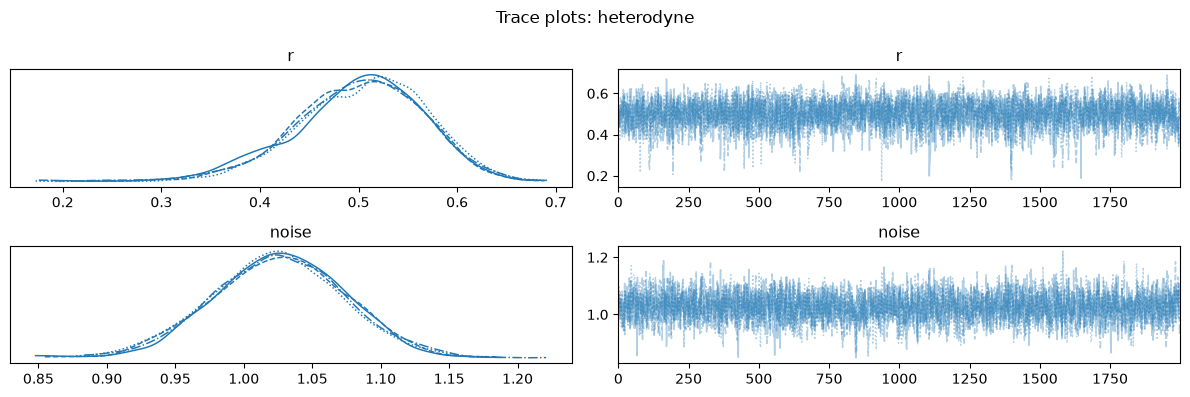

C:\Users\kanci\AppData\Local\Temp\ipykernel_9256\657810364.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


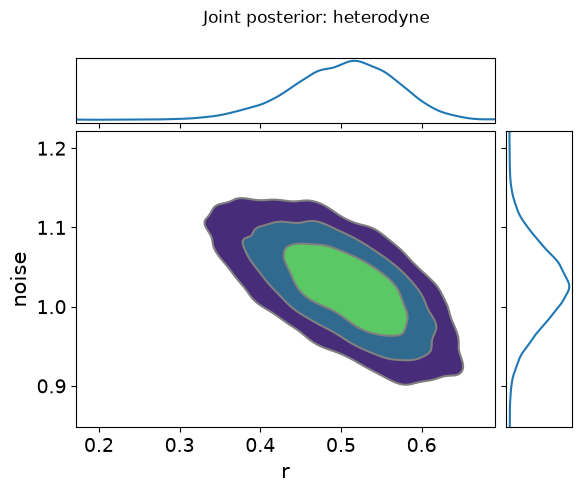

In [18]:
for mt, mcmc in results.items():

    idata = az.from_numpyro(mcmc)

    # Marginal posterior distributions
    az.plot_posterior(
        idata,
        var_names=["r", "noise"],
        ref_val=None,
    )

    plt.suptitle(f"Posterior distributions: {mt}")
    plt.tight_layout()
    plt.show()

    # Trace plots
    az.plot_trace(
        idata,
        var_names=["r", "noise"],
        compact=True,
    )

    plt.suptitle(f"Trace plots: {mt}")
    plt.tight_layout()
    plt.show()

    # Joint posterior: trade-off between r and noise
    az.plot_pair(
        idata,
        var_names=["r", "noise"],
        kind="kde",
        marginals=True,
    )

    plt.suptitle(f"Joint posterior: {mt}")
    plt.tight_layout()
    plt.show()

***
## Inference from Betti curves (topological summary)

The models above use the raw quadratures. Here the same datasets are reduced to their **Betti curves** $\beta_0(t), \beta_1(t)$ (Section 3.2, `homology.py`), and $r$ is inferred from those alone, as described in the abstract.

Betti curves have no closed-form likelihood, so we use a **synthetic likelihood** (`topological_inference.py`): simulate datasets with $r \sim \mathcal{U}(0, 1)$ through the same measurement chain, compute their Betti curves on fixed grids, compress them with PCA to $z$, and fit $z \mid r \sim \mathcal{N}(m(r), C)$ with $m(r)$ a cubic polynomial and $C$ the pooled residual covariance. This emulator is then the likelihood in a numpyro model, sampled with NUTS as before.

The detector noise is fixed at its **calibration estimate** $\hat\sigma$ from the posterior above (not the true value). Training takes ~2-3 minutes per scheme; ripser runs in parallel worker processes.

In [19]:
import topological_inference as ti
import metrics

r_max = 1.0  # same Uniform(0, 1) prior as the models above

emulators, training, sigma_hat = {}, {}, {}
for i, mt in enumerate(measurement_types):
    sigma_hat[mt] = float(np.mean(results[mt].get_samples()["noise"]))
    emulators[mt], r_train, z_train = ti.fit_emulator(
        mt, n_samples, sigma_hat[mt], random.fold_in(random.key(200), i), r_max=r_max)
    training[mt] = (r_train, z_train)
    print(f"{mt}: sigma_hat = {sigma_hat[mt]:.3f}, "
          f"grids up to t = {emulators[mt].grids[0][-1]:.2f} (H0), {emulators[mt].grids[1][-1]:.2f} (H1)")

joint: sigma_hat = 1.004, grids up to t = 2.72 (H0), 2.50 (H1)


heterodyne: sigma_hat = 1.025, grids up to t = 3.16 (H0), 2.82 (H1)


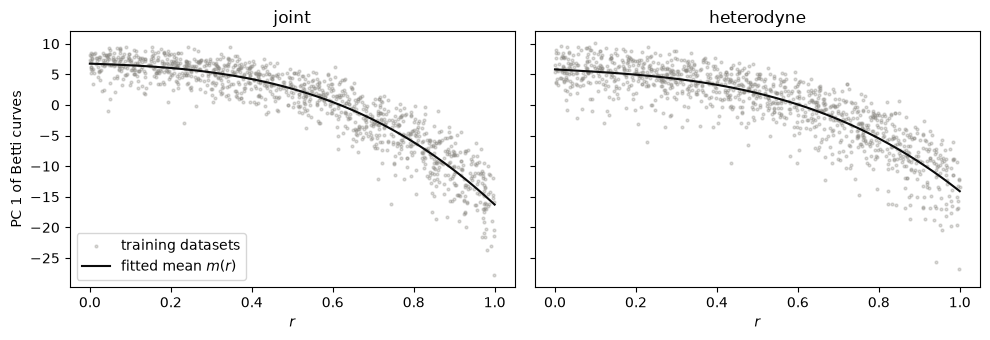

In [20]:
# Emulator check: the leading PCA component of the Betti curves against r, with the fitted mean m(r)
fig, axes = plt.subplots(1, len(measurement_types), figsize=(10, 3.5), sharey=True)
r_line = np.linspace(0, r_max, 200)
for ax, mt in zip(axes, measurement_types):
    r_train, z_train = training[mt]
    ax.scatter(r_train, z_train[:, 0], s=4, alpha=0.3, color="#898781", label="training datasets")
    ax.plot(r_line, np.asarray(jax.vmap(emulators[mt].mean)(jnp.asarray(r_line)))[:, 0],
            color="#0b0b0b", lw=1.5, label="fitted mean $m(r)$")
    ax.set(title=mt, xlabel="$r$")
axes[0].set_ylabel("PC 1 of Betti curves")
axes[0].legend()
plt.tight_layout()
plt.show()

In [21]:
# Posterior of r given only the Betti curves of the observed datasets (same data as the models above)
betti_results, z_obs = {}, {}
observed_diagrams = ti.persistence_diagrams([np.asarray(datasets[mt]["X_obs"]) for mt in measurement_types])

for i, mt in enumerate(measurement_types):
    z_obs[mt] = emulators[mt].summarise(observed_diagrams[i])
    mcmc = MCMC(NUTS(ti.make_betti_model(emulators[mt], r_max), target_accept_prob=0.9),
                num_warmup=1000, num_samples=2000, num_chains=4, progress_bar=False)
    mcmc.run(random.fold_in(random.key(300), i), z_obs=jnp.asarray(z_obs[mt]))
    betti_results[mt] = mcmc
    print(f"\nBetti-curve posterior: {mt}")
    print(az.summary(az.from_numpyro(mcmc), var_names=["r"], hdi_prob=0.90))


Betti-curve posterior: joint


    mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r  0.349  0.135   0.113    0.553      0.004    0.003    1288.0    1056.0   

   r_hat  
r    1.0  



Betti-curve posterior: heterodyne


    mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r  0.456  0.137    0.24    0.676      0.004    0.003    1548.0    1224.0   

   r_hat  
r    1.0  


True r: 0.5
measurement                        method  r_mean  r_median  r_sd  r_90%_low  r_90%_high
      joint raw quadratures + calibration   0.492     0.494 0.045      0.415       0.563
      joint                  Betti curves   0.349     0.372 0.135      0.082       0.535
 heterodyne raw quadratures + calibration   0.501     0.506 0.066      0.387       0.600
 heterodyne                  Betti curves   0.456     0.478 0.137      0.179       0.639


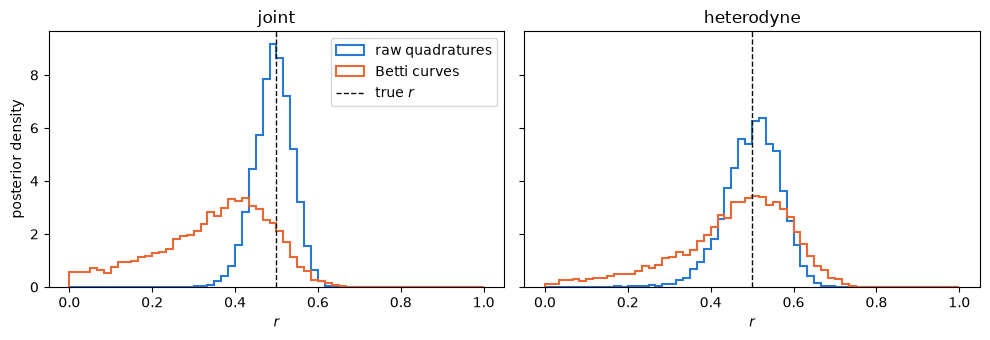

In [22]:
rows = []
for mt in measurement_types:
    for method, mcmc in (("raw quadratures + calibration", results[mt]), ("Betti curves", betti_results[mt])):
        r_s = np.asarray(mcmc.get_samples()["r"])
        lo, hi = np.percentile(r_s, [5, 95])
        rows.append({"measurement": mt, "method": method, "r_mean": r_s.mean(), "r_median": np.median(r_s),
                     "r_sd": r_s.std(), "r_90%_low": lo, "r_90%_high": hi})
print("True r:", r_true)
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(measurement_types), figsize=(10, 3.5), sharey=True)
for ax, mt in zip(axes, measurement_types):
    for label, mcmc, color in (("raw quadratures", results[mt], "#2a78d6"),
                               ("Betti curves", betti_results[mt], "#eb6834")):
        ax.hist(np.asarray(mcmc.get_samples()["r"]), bins=60, range=(0, r_max), density=True,
                histtype="step", lw=1.5, color=color, label=label)
    ax.axvline(r_true, color="#0b0b0b", ls="--", lw=1, label="true $r$")
    ax.set(title=mt, xlabel="$r$")
axes[0].set_ylabel("posterior density")
axes[0].legend()
plt.tight_layout()
plt.show()

### Repeated datasets: accuracy, calibration and the Cramér–Rao bound

One dataset cannot show whether the posteriors are reliable. Below, both methods are applied to many independent datasets at the same $r$, with the noise fixed at $\hat\sigma$. Since $r$ is one-dimensional, each posterior is computed exactly on a grid (`ti.grid_posterior`) instead of by MCMC. Reported per method: the RMSE of the posterior mean, the average posterior sd, and the **coverage** (fraction of 90% intervals containing the true $r$; about 0.90 means calibrated uncertainties). The Cramér–Rao bound (`metrics.squeezing_crb`, Section 3.1) is the smallest error any unbiased estimator can reach from the raw data, so the gap between the Betti-curve error and this bound measures how much information the topological summary discards.

In [23]:
n_repeats = 40
r_grid = np.linspace(0.0, r_max, 401)

repeat_rows = []
for i, mt in enumerate(measurement_types):
    clouds = ti.simulate_clouds(np.full(n_repeats, r_true), n_samples, noise_true, mt, random.fold_in(random.key(400), i))
    diagrams = ti.persistence_diagrams(clouds)
    emu = emulators[mt]
    betti_ll = jax.jit(jax.vmap(emu.log_likelihood, in_axes=(0, None)))
    posts = {
        "raw quadratures": [ti.grid_posterior(ti.quadrature_log_likelihood(c, r_grid, sigma_hat[mt], mt), r_grid)
                            for c in clouds],
        "Betti curves": [ti.grid_posterior(betti_ll(jnp.asarray(r_grid), jnp.asarray(emu.summarise(d))), r_grid)
                         for d in diagrams],
    }
    for method, ps in posts.items():
        means = np.array([p["mean"] for p in ps])
        repeat_rows.append({
            "measurement": mt, "method": method,
            "rmse": np.sqrt(np.mean((means - r_true) ** 2)),
            "bias": np.mean(means - r_true),
            "mean_posterior_sd": np.mean([p["sd"] for p in ps]),
            "coverage_90%": np.mean([p["low"] <= r_true <= p["high"] for p in ps]),
            "crb": float(metrics.squeezing_crb(r_true, n_samples, sigma_hat[mt], mt)),
        })
repeat_df = pd.DataFrame(repeat_rows)
repeat_df["rmse / crb"] = repeat_df["rmse"] / repeat_df["crb"]
print(f"True r = {r_true}, N = {n_samples}, true noise = {noise_true}, {n_repeats} datasets per scheme")
print(repeat_df.round(3).to_string(index=False))

True r = 0.5, N = 1000, true noise = 1.0, 40 datasets per scheme
measurement          method  rmse   bias  mean_posterior_sd  coverage_90%   crb  rmse / crb
      joint raw quadratures 0.033 -0.010              0.035         0.875 0.034       0.963
      joint    Betti curves 0.104 -0.055              0.112         0.950 0.034       3.027
 heterodyne raw quadratures 0.059 -0.029              0.054         0.900 0.048       1.230
 heterodyne    Betti curves 0.134 -0.073              0.132         0.925 0.048       2.766


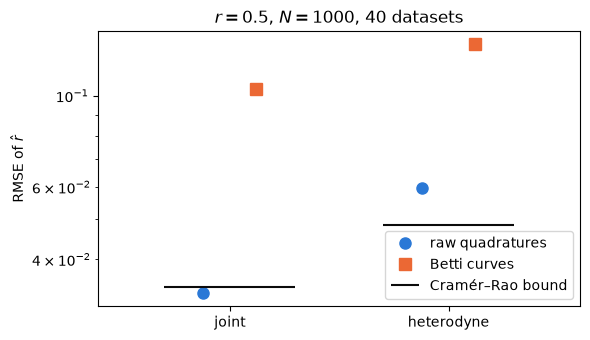

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
styles = {"raw quadratures": dict(color="#2a78d6", marker="o"), "Betti curves": dict(color="#eb6834", marker="s")}
for j, mt in enumerate(measurement_types):
    sub = repeat_df[repeat_df.measurement == mt]
    for k, (method, st) in enumerate(styles.items()):
        ax.plot(j + 0.12 * (2 * k - 1), sub[sub.method == method]["rmse"].item(), ls="none", ms=8,
                label=method if j == 0 else None, **st)
    ax.hlines(sub["crb"].iloc[0], j - 0.3, j + 0.3, color="#0b0b0b", lw=1.5,
              label="Cramér–Rao bound" if j == 0 else None)
ax.set(xticks=range(len(measurement_types)), xticklabels=measurement_types, xlim=(-0.6, len(measurement_types) - 0.4),
       yscale="log", ylabel=r"RMSE of $\hat r$", title=f"$r = {r_true}$, $N = {n_samples}$, {n_repeats} datasets")
ax.legend()
plt.tight_layout()
plt.show()

**Reading the results.** The Betti curves do recover $r$, but with a larger error than the raw quadratures, which sit at the Cramér–Rao bound: the topological summary discards information. The reason is that the quadrature cloud is a Gaussian blob with no non-trivial topology; its Betti curves respond to $r$ only through the overall scale of the cloud (its width grows as $\sqrt{\cosh 2r + c}$), which the raw-data likelihood already uses optimally. Coverage near 0.90 shows the synthetic-likelihood uncertainties are calibrated. The negative bias of the posterior means comes from the posterior's skew: near $r = 0$ the data depend only weakly on $r$, so the posterior has a long tail towards small $r$; the effect is larger for the less informative Betti-curve summary.